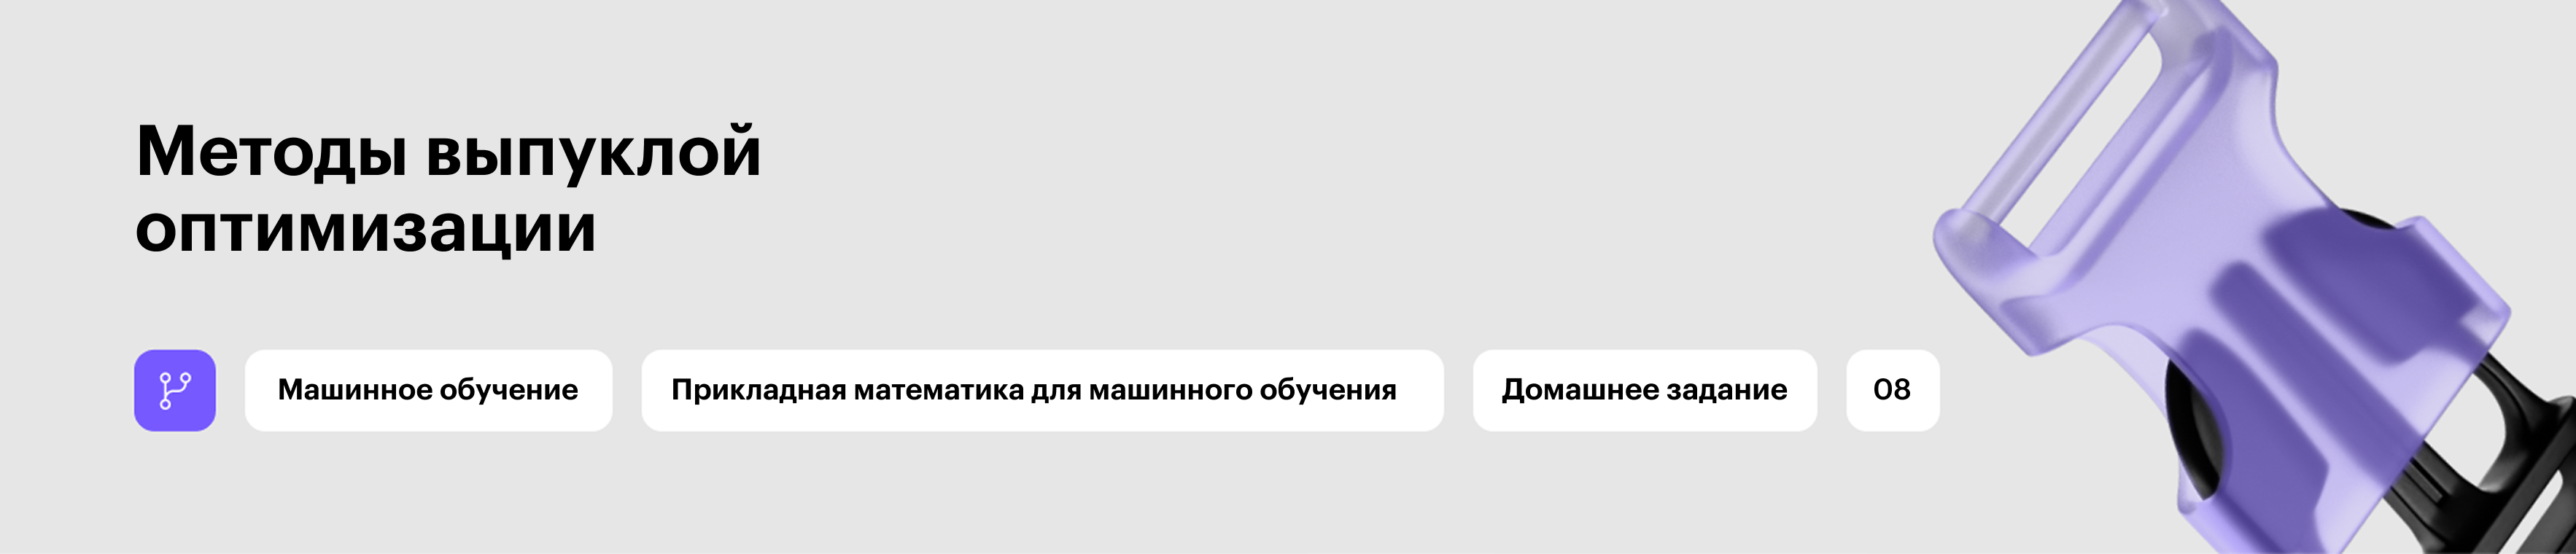

## Домашнее задание 10. Методы оптимизации первого порядка. Начало (2,5 балла)

# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используй данный шаблон.</font>**

    ✅ Можно добавлять новые ячейки любых типов.
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий.


🔷 **<font color='plum'>При оценивании задач учитывается код.</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами «Your code here» / «Твой код» и аналогичными.
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов.
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно.

🔷 **<font color='plum'>При оценивании задач учитываются выводы.</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами «Вывод» / «Ответ на вопрос» / «Твой текст» и аналогичными.
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать Markdown, LaTeX).
    ✅ Сопутствующие изображения, графики, таблички приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл.

## <font color='DarkOrange'> **Задание 1 [1,5 балла]**</font>

Сравни скорости сходимости градиентных методов для двух разных функций:


-  $f_1(x) = x_1^2 + x_2^2$,
-  $f_2(x) = 100x_1^2 + x_2^2$.

Условия градиентного спуска
- Стартовая точка  $x^0=(10.8)$.
- Критерий останова $|f(x^k) - f(x^*)| < 10^{-4}$.
- Параметры для дробления шага можешь выбрать самостоятельно.

Для сравнения скорости сходимости на функциях необходимо:
- предоставить число итераций градиентного спуска, за которое было получено желаемое по точности решение;
- изобразить графически зависимость $|f^* - f(x_k)|$ от количества шагов для каждой функции (line plot) (тут необходимо будет найти f^* самостоятельно, можно аналитически);
- изобразить траекторию точек $x_k$ на графике линии уровней функций (см. пример с семинара).

Алгоритмы градиентного спуска

А. <font color='DarkOrange'> **[0,75 балла]**</font> Сравнить скорости для градиентного спуска с дискретным шагом.

Б. <font color='DarkOrange'> **[0,75 балла]**</font> Сравнить скорости для градиентного спуска с дроблением шага.


<font color='MediumTurquoise'>**Tip:**</font> можно взять часть кода с семинара, для реализации критерия останова необходимо знать точное решение, при неверном выборе шага решение может разойтись.


In [1]:
import numpy as np

In [2]:
def f1(x):
  return x[0] ** 2 + x[1] ** 2

In [3]:
def f2(x):
  return 100*x[0] ** 2 + x[1] ** 2

In [4]:
x0 = np.array([10,8])

Дискретный шаг f1
Шаг: 0.5
Количество итераций: 1
Точка минимума: [0. 0.]
Ошибка: 0.0

Дискретный шаг f2
Шаг: 0.005
Количество итераций: 666
Точка минимума: [0.         0.00991128]
Ошибка: 9.82334004644923e-05



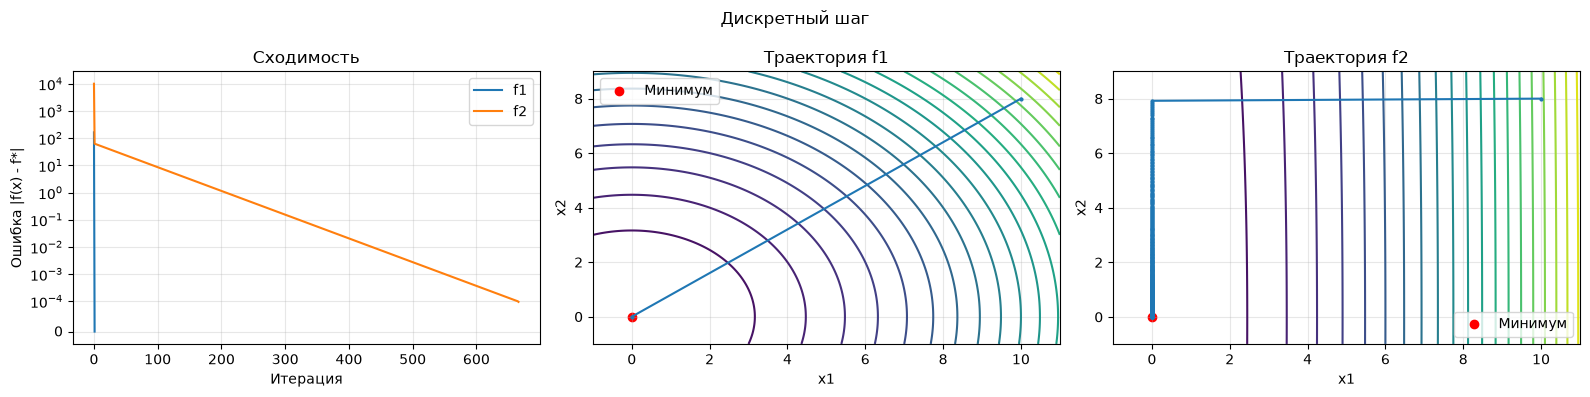

Дробление шага f1
Количество итераций: 1
Точка минимума: [0. 0.]
Ошибка: 0.0

Дробление шага f2
Количество итераций: 853
Точка минимума: [0.         0.00994397]
Ошибка: 9.888256093660511e-05



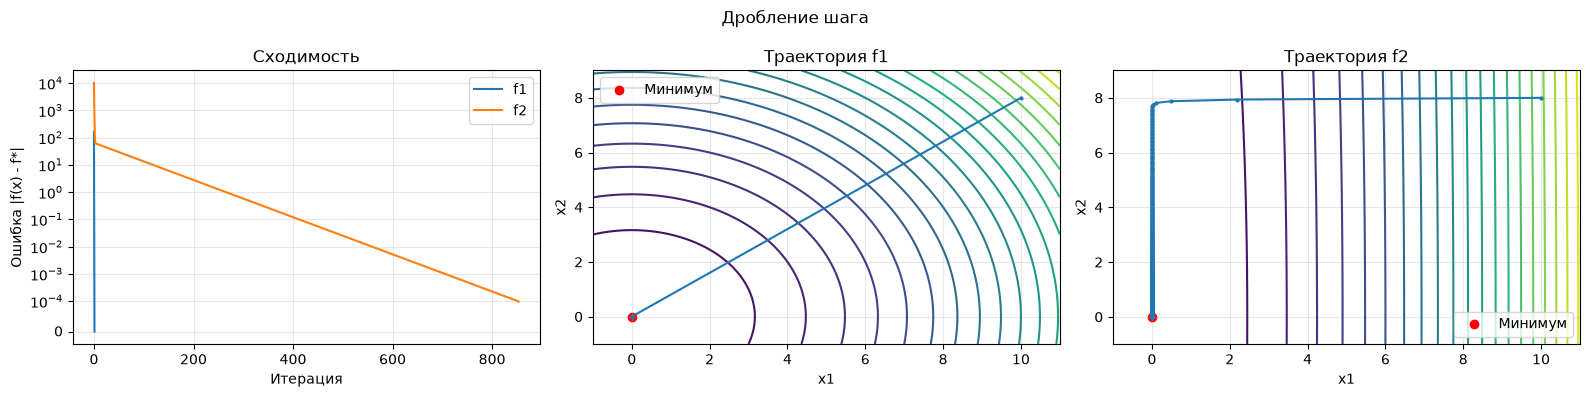

In [5]:
# Your code here
import matplotlib.pyplot as plt


def grad_f1(x):
    return 2 * x


def grad_f2(x):
    return np.array([200 * x[0], 2 * x[1]])


def gradient_descent(f, grad_f, x0, alpha, crushing=False,
                     beta=1, lamda=0.5, epsilon=0.5,
                     tolerance=1e-4, max_iter=100_000):
    x = x0.astype(float).copy()
    history = [x.copy()]
    step = beta if crushing else alpha

    for i in range(max_iter):
        if abs(f(x) - f_star) < tolerance:
            return x, np.array(history)

        grad = grad_f(x)

        if crushing:
            while f(x - step * grad) > f(x) - epsilon * step * np.dot(grad, grad):
                step *= lamda

        x = x - step * grad
        history.append(x.copy())

    if abs(f(x) - f_star) >= tolerance:
        raise RuntimeError("Не достигнута заданная точность")
    return x, np.array(history)


f_star = 0
functions = [(f1, grad_f1, 0.5, "f1"), (f2, grad_f2, 0.005, "f2")]
results = {}

for crushing, method in [(False, "Дискретный шаг"), (True, "Дробление шага")]:
    plt.figure(figsize=(16, 4))

    for number, (f, grad_f, alpha, name) in enumerate(functions, start=1):
        x, history = gradient_descent(f, grad_f, x0, alpha, crushing=crushing)
        errors = np.array([abs(f(point) - f_star) for point in history])
        results[(method, name)] = (x, history, errors)

        print(method, name)
        if not crushing:
            print("Шаг:", alpha)
        print("Количество итераций:", len(history) - 1)
        print("Точка минимума:", x)
        print("Ошибка:", errors[-1])
        print()

        plt.subplot(1, 3, 1)
        plt.plot(errors, label=name)

        plt.subplot(1, 3, number + 1)
        x1 = np.linspace(history[:, 0].min() - 1, history[:, 0].max() + 1, 200)
        x2 = np.linspace(history[:, 1].min() - 1, history[:, 1].max() + 1, 200)
        X1, X2 = np.meshgrid(x1, x2)
        Z = f([X1, X2])

        plt.contour(X1, X2, Z, levels=20)
        plt.plot(history[:, 0], history[:, 1], "o-", markersize=2)
        plt.scatter(0, 0, color="red", label="Минимум")
        plt.xlabel("x1")
        plt.ylabel("x2")
        plt.title(f"Траектория {name}")
        plt.legend()
        plt.grid(alpha=0.3)

    plt.subplot(1, 3, 1)
    plt.yscale("symlog", linthresh=1e-4)
    plt.xlabel("Итерация")
    plt.ylabel("Ошибка |f(x) - f*|")
    plt.title("Сходимость")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.suptitle(method)
    plt.tight_layout()
    plt.show()


## <font color='DarkOrange'> **Задание 2 [1 балл]**</font>

Сравни скорость (во временном эквиваленте) и ответы решения задачи линейной регресии $$\|y - Xw \| \to \min_{w}$$
аналитическим (явная формула) и градиентным методами (дискретный шаг).

Условия градиентного спуска
- Стартовая точка  $w^0$ задана случайно в условии.
- Критерий останова $\|\nabla f(w^k)\| < 10^{-4}$.
- Параметр $\alpha$ можно подбирать.

<font color='MediumTurquoise'>**Tip:**</font>
не всегда градиентный метод может быть эффективнее.


In [6]:
import numpy as np

In [7]:
rng = np.random.default_rng(2025)

In [8]:
# Зададим зависимость
w_size = 4
x_size = 100_000
X = rng.uniform(0, 1, (x_size, w_size))
w_sol = np.arange(w_size) + 1
Y = X @ w_sol + rng.random(x_size) * 0.5

In [9]:
w_sol

array([1, 2, 3, 4])

In [10]:
# Начальная точка
w0 = rng.random(w_size)

Минимизируем $f(w)=\frac{1}{N}\|Xw-Y\|_2^2$: минимум достигается при тех же весах, что и у $\|Xw-Y\|_2$. Тогда $\nabla f(w)=\frac{2}{N}X^T(Xw-Y)$, а аналитическое решение $w^*=(X^TX)^{-1}X^TY$. Критерий останова применяем к градиенту MSE.

In [11]:
# Your code here
from time import perf_counter


start = perf_counter()
w_analytic = np.linalg.inv(X.T @ X) @ (X.T @ Y)
time_analytic = perf_counter() - start

alpha = 0.5
tolerance = 1e-4
max_iter = 100_000

start = perf_counter()
w = w0.copy()
iterations = 0

for i in range(max_iter):
    grad = 2 / x_size * X.T @ (X @ w - Y)
    if np.linalg.norm(grad) < tolerance:
        break

    w = w - alpha * grad
    iterations += 1
else:
    raise RuntimeError("Не достигнута заданная точность")

time_gradient = perf_counter() - start

print("Аналитическое решение:", w_analytic)
print("Градиентный спуск:", w)
print(f"Время аналитического решения: {time_analytic:.6f} с")
print(f"Время градиентного спуска: {time_gradient:.6f} с")
print("Количество итераций:", iterations)
print("Норма градиента:", np.linalg.norm(grad))
print("Расстояние между решениями:", np.linalg.norm(w - w_analytic))
print("MSE аналитического решения:", np.mean((X @ w_analytic - Y) ** 2))
print("MSE градиентного спуска:", np.mean((X @ w - Y) ** 2))
print("Быстрее:", "аналитический метод" if time_analytic < time_gradient else "градиентный спуск")


Аналитическое решение: [1.11607327 2.11580163 3.1157841  4.1138774 ]
Градиентный спуск: [1.11650114 2.11586244 3.11568567 4.11348847]
Время аналитического решения: 0.000816 с
Время градиентного спуска: 0.039733 с
Количество итераций: 96
Норма градиента: 9.775361777677724e-05
Расстояние между решениями: 0.0005896770507116376
MSE аналитического решения: 0.025774919000217843
MSE градиентного спуска: 0.025774947821467664
Быстрее: аналитический метод


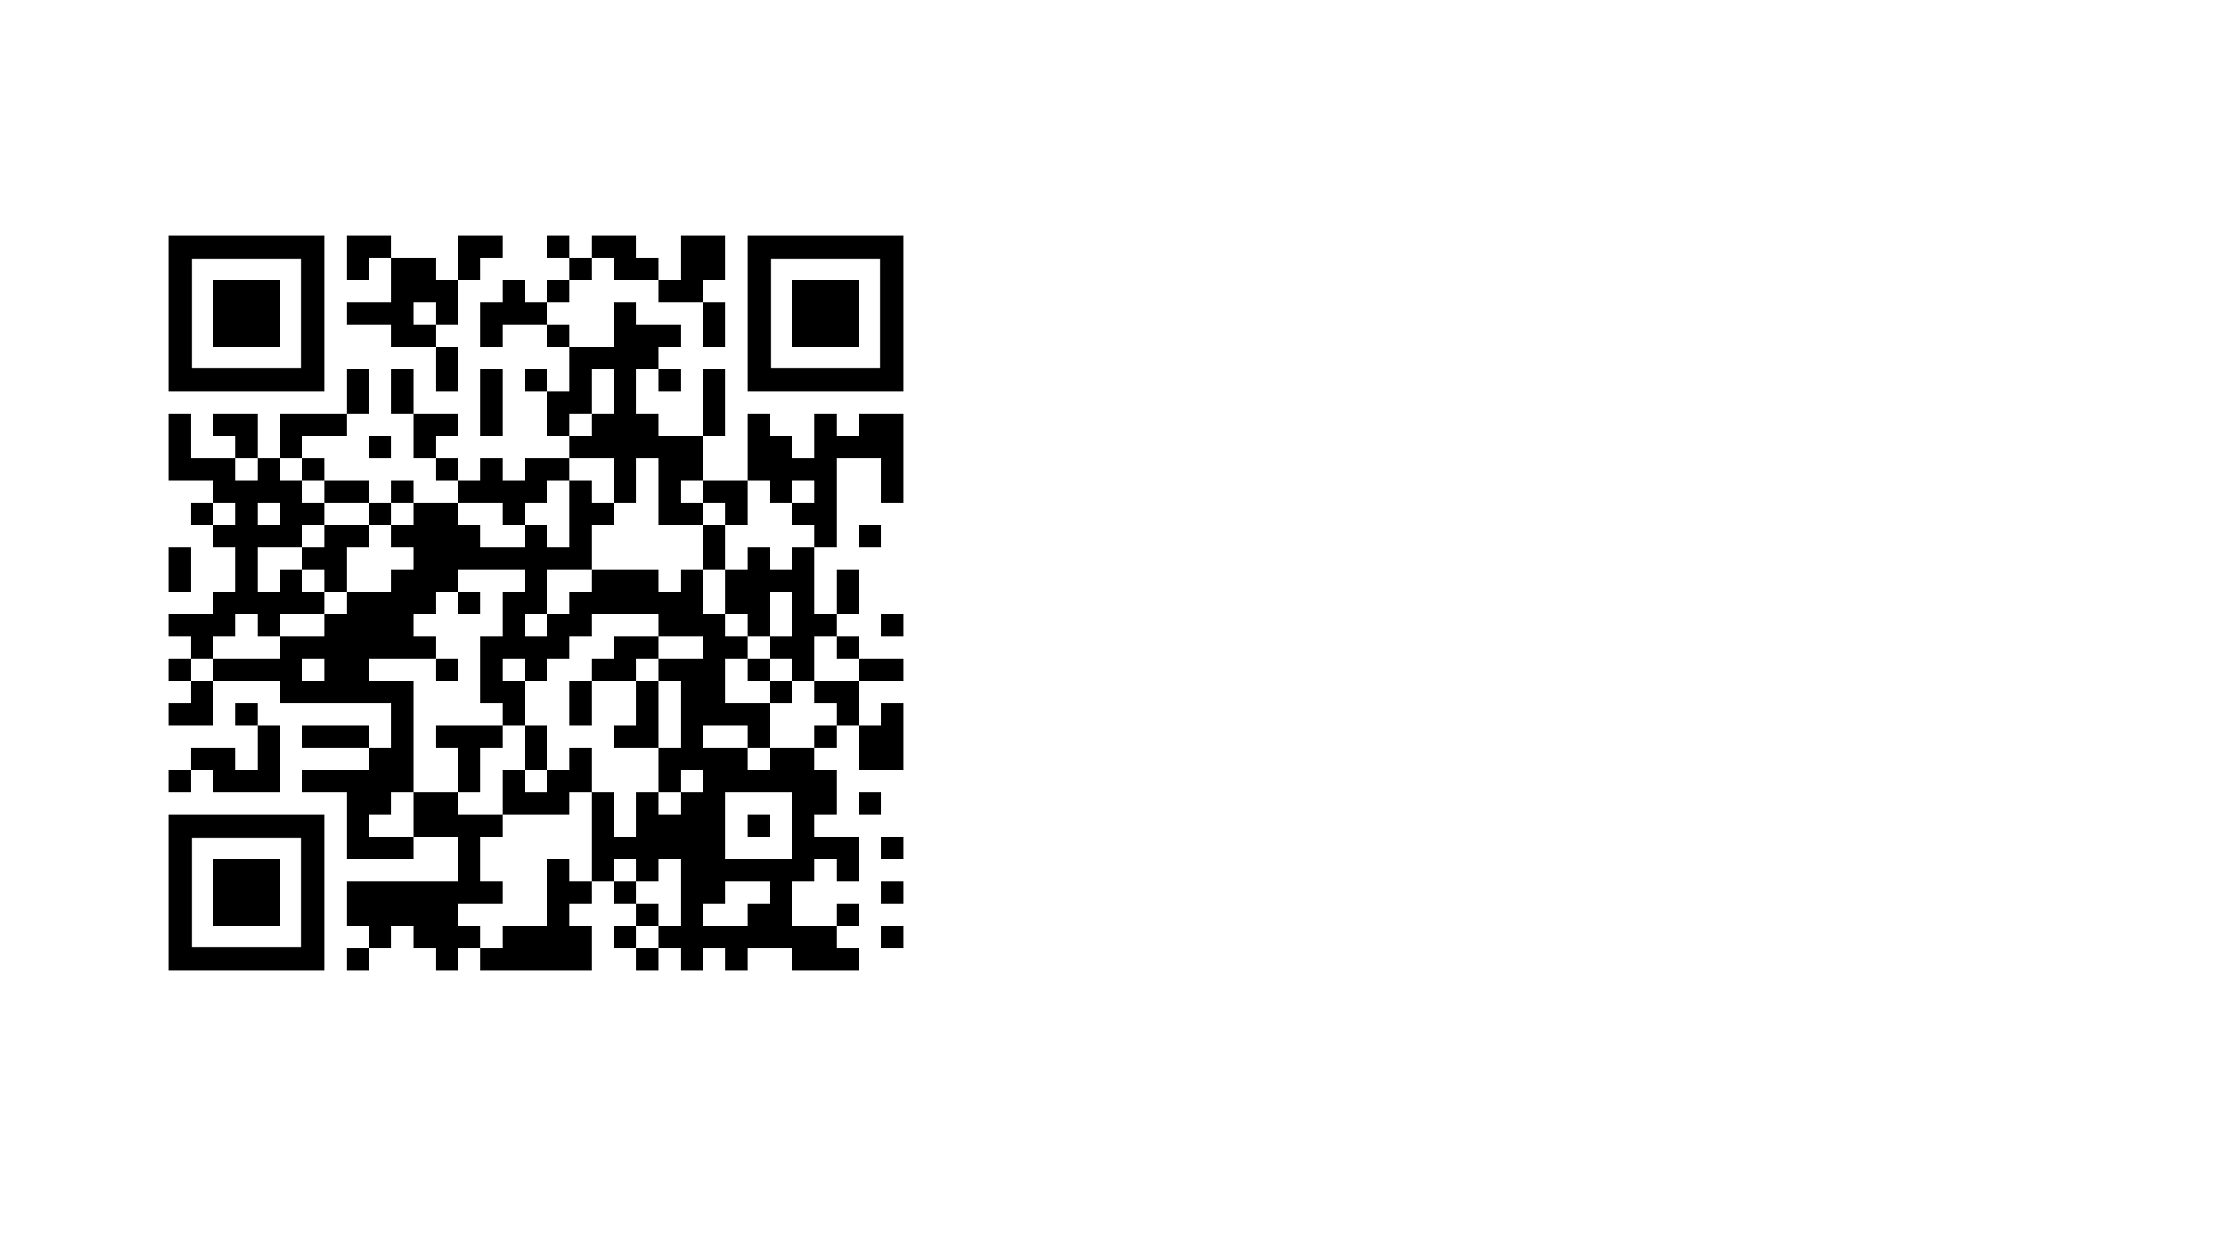